# **Energy Demand Intelligence**

Este notebook reúne el ciclo analítico de extremo a extremo bajo CRISP-DM. Las fases se conectan y pueden iterar. Los resultados creados en una sección alimentan las siguientes dentro del mismo entorno, y solo se guardan los artefactos necesarios para reproducir el análisis o alimentar el dashboard. Para reproducir el flujo, ejecutar las celdas de arriba hacia abajo.

## **1. Business understanding**

La solución parte de una necesidad de negocio: comprender el comportamiento de la demanda eléctrica, anticipar su evolución y convertir los resultados en información útil para la planificación. Esta fase fija el problema y los criterios con los que se juzgará el trabajo analítico.

### **1.1. Contexto y necesidad de negocio**

El proyecto utiliza registros históricos de consumo de tres redes de distribución de Tétouan, Marruecos. El objetivo es construir un caso de analítica reproducible que conecte el análisis de datos, el pronóstico y la comunicación de hallazgos en un dashboard. El dataset no identifica una empresa operadora ni incluye por sí solo costos, capacidad de red o eventos operativos.

### **1.2. Pregunta de negocio y objetivos analíticos**

¿Hasta qué punto los registros históricos de diez minutos de las tres redes observadas de Tétouan permiten pronosticar su carga eléctrica a 24 horas y a siete días, identificar periodos de demanda inusualmente alta y determinar si las variables meteorológicas aportan valor predictivo frente a una línea base temporal?

El análisis debe describir patrones temporales, comparar el comportamiento por zona, establecer una línea base de forecasting y determinar si los modelos candidatos aportan una mejora medible fuera de muestra.

### **1.3. Criterios de éxito y límites**

El proyecto avanza si produce hallazgos trazables, compara las predicciones con una línea base bajo particiones cronológicas y evalúa el desempeño por zona y horizonte. Las conclusiones deben distinguir observaciones, hipótesis y recomendaciones. El histórico de 2017 no demuestra desempeño operativo en 2026, y no permite afirmar ahorros, costos evitados ni riesgo físico de sobrecarga sin datos adicionales.

### **1.4. Ruta del proyecto según CRISP-DM**

| Fase | Propósito en este proyecto | Estado |
|---|---|---|
| Business Understanding | Definir pregunta, decisiones y criterios de éxito | Definido en el brief |
| Data Understanding | Auditar la fuente, su calidad y patrones iniciales | En desarrollo en este notebook |
| Data Preparation | Justificar reglas de limpieza, agregación y variables | Pendiente de resolver hallazgos de la fase 2 |
| Modeling | Construir baselines y comparar modelos candidatos | Pendiente |
| Evaluation | Evaluar utilidad fuera de muestra y limitaciones | Pendiente |
| Deployment | Preparar un flujo reproducible para el dashboard y su seguimiento | Pendiente |

El marco CRISP-DM también contempla evaluar la situación, inventariar recursos y restricciones, describir y verificar los datos, seleccionar y construir el dataset, diseñar pruebas, evaluar resultados frente a criterios de éxito, definir el despliegue y planear la monitorización. La guía visual adjunta presenta estas actividades como tareas generales que deben adaptarse al proyecto, no como pasos obligatorios e idénticos para todos los casos.

La pregunta de negocio define qué se debe observar. La fase siguiente verifica si la fuente realmente permite responderla y documenta las limitaciones antes de transformar o modelar datos.

## **2. Data understanding**

Esta fase confirma la estructura, integridad, cobertura y comportamiento inicial de los datos. Los resultados se interpretan en contexto y las anomalías se conservan como preguntas de investigación hasta que exista evidencia para tratarlas.

### **2.1. Preparar el entorno**

Se centralizan aquí las importaciones, las rutas y los nombres de variables. El código busca primero el archivo dentro de la estructura del repositorio, luego en ubicaciones habituales de ejecución local y, si corre en Google Colab, permite cargar el CSV manualmente.

Las carpetas de salida se crean con una estructura estable para que las tablas, los gráficos y el dataset estandarizado puedan versionarse y encontrarse fácilmente.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

DATA_FILENAME = "Tetuan City power consumption.csv"


def find_project_root() -> Path:
    """Find the repository root when the notebook runs locally or in Colab."""
    candidates = [Path.cwd(), Path.cwd().parent, Path("/mnt/data/energy_demand_intelligence_repo")]
    for candidate in candidates:
        if (candidate / "data" / "raw" / DATA_FILENAME).exists():
            return candidate.resolve()
    return Path.cwd().resolve()


PROJECT_ROOT = find_project_root()
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
TABLES_DIR = PROJECT_ROOT / "reports" / "tables"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

for folder in [PROCESSED_DATA_DIR, TABLES_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

possible_paths = [
    RAW_DATA_DIR / DATA_FILENAME,
    Path.cwd() / DATA_FILENAME,
    Path("/mnt/data") / DATA_FILENAME,
]
DATA_PATH = next((path for path in possible_paths if path.exists()), None)

if DATA_PATH is None:
    try:
        from google.colab import files
        uploaded = files.upload()
        if DATA_FILENAME in uploaded:
            DATA_PATH = Path(DATA_FILENAME)
        else:
            csv_files = [Path(name) for name in uploaded if name.lower().endswith(".csv")]
            if len(csv_files) == 1:
                DATA_PATH = csv_files[0]
            else:
                raise FileNotFoundError(
                    f"Carga exactamente el archivo esperado: {DATA_FILENAME}"
                )
    except ImportError as exc:
        raise FileNotFoundError(
            f"No se encontró {DATA_FILENAME}. Coloca el archivo en data/raw/ o junto al notebook."
        ) from exc

data_path_display = DATA_PATH.relative_to(PROJECT_ROOT) if DATA_PATH.is_relative_to(PROJECT_ROOT) else Path(DATA_PATH.name)
print(f"Raíz del proyecto: {PROJECT_ROOT.name}")
print(f"Archivo de entrada: {data_path_display}")
print(f"Tablas de salida: {TABLES_DIR}")
print(f"Gráficos de salida: {FIGURES_DIR}")

Raíz del proyecto: energy_demand_intelligence_repo
Archivo de entrada: data\raw\Tetuan City power consumption.csv
Tablas de salida: C:\Users\camil\Escritorio\energy_demand_intelligence_repo\reports\tables
Gráficos de salida: C:\Users\camil\Escritorio\energy_demand_intelligence_repo\reports\figures


### **2.2. Cargar y revisar la estructura original**

El primer control consiste en confirmar que el archivo tiene las columnas esperadas. Se guardan los nombres originales para mantener trazabilidad. Solo se estandarizan los nombres para facilitar el uso posterior en Python y se convierte la marca de tiempo al tipo datetime. Los valores de consumo y meteorología permanecen intactos.

In [2]:
raw = pd.read_csv(DATA_PATH)
original_columns = raw.columns.tolist()

rename_map = {
    "DateTime": "datetime",
    "Temperature": "temperature",
    "Humidity": "humidity",
    "Wind Speed": "wind_speed",
    "general diffuse flows": "general_diffuse_flows",
    "diffuse flows": "diffuse_flows",
    "Zone 1 Power Consumption": "zone_1_load",
    "Zone 2  Power Consumption": "zone_2_load",
    "Zone 3  Power Consumption": "zone_3_load",
}

missing_expected = sorted(set(rename_map) - set(original_columns))
if missing_expected:
    raise ValueError(f"El archivo no contiene las columnas esperadas: {missing_expected}")

# No se sobrescribe ni se edita el archivo de origen.
df = raw.rename(columns=rename_map).copy()
df["datetime"] = pd.to_datetime(
    df["datetime"], format="mixed", dayfirst=False, errors="coerce"
)

if df["datetime"].isna().any():
    raise ValueError("Hay marcas de tiempo que no pudieron interpretarse. Revisar DateTime.")

load_cols = ["zone_1_load", "zone_2_load", "zone_3_load"]
weather_cols = [
    "temperature",
    "humidity",
    "wind_speed",
    "general_diffuse_flows",
    "diffuse_flows",
]

schema = pd.DataFrame({
    "variable": df.columns,
    "tipo": [str(dtype) for dtype in df.dtypes],
    "valores_no_nulos": [int(df[col].notna().sum()) for col in df.columns],
    "valores_nulos": [int(df[col].isna().sum()) for col in df.columns],
    "valores_distintos": [int(df[col].nunique(dropna=True)) for col in df.columns],
})

print(f"Dimensiones observadas: {df.shape[0]:,} filas y {df.shape[1]} columnas")
display(schema)
display(df.head(8))

Dimensiones observadas: 52,416 filas y 9 columnas


,variable,tipo,valores_no_nulos,valores_nulos,valores_distintos
0,datetime,datetime64[ns],52416,0,52416
1,temperature,float64,52416,0,3437
2,humidity,float64,52416,0,4443
3,wind_speed,float64,52416,0,548
4,general_diffuse_flows,float64,52416,0,10504
5,diffuse_flows,float64,52416,0,10449
6,zone_1_load,float64,52416,0,27709
7,zone_2_load,float64,52416,0,29621
8,zone_3_load,float64,52416,0,22838


,datetime,temperature,humidity,wind_speed,general_diffuse_flows,diffuse_flows,zone_1_load,zone_2_load,zone_3_load
0,2017-01-01 00:00:00,6.559,73.800,0.083,0.051,0.119,"34,055.696","16,128.875","20,240.964"
1,2017-01-01 00:10:00,6.414,74.500,0.083,0.070,0.085,"29,814.684","19,375.076","20,131.084"
2,2017-01-01 00:20:00,6.313,74.500,0.080,0.062,0.100,"29,128.101","19,006.687","19,668.434"
3,2017-01-01 00:30:00,6.121,75.000,0.083,0.091,0.096,"28,228.861","18,361.094","18,899.277"
4,2017-01-01 00:40:00,5.921,75.700,0.081,0.048,0.085,"27,335.696","17,872.340","18,442.410"
5,2017-01-01 00:50:00,5.853,76.900,0.081,0.059,0.108,"26,624.810","17,416.413","18,130.120"
6,2017-01-01 01:00:00,5.641,77.700,0.080,0.048,0.096,"25,998.987","16,993.313","17,945.060"
7,2017-01-01 01:10:00,5.496,78.200,0.085,0.055,0.093,"25,446.076","16,661.398","17,459.277"


### **2.3. Auditar integridad y cobertura temporal**

La calidad de una serie temporal requiere revisar algo más que nulos. Este bloque comprueba duplicados, frecuencia entre marcas de tiempo y cobertura frente al año calendario 2017. El control distingue los intervalos internos entre registros de la cobertura completa esperada. Una serie puede ser regular durante todo el periodo disponible y aun así estar incompleta al final.

In [3]:
EXPECTED_FREQUENCY = pd.Timedelta(minutes=10)
EXPECTED_ROWS_2017 = 365 * 24 * 6
UCI_REPORTED_ROWS = 52_417

sorted_timestamps = df["datetime"].sort_values()
intervals = sorted_timestamps.diff().dropna()

quality_audit = pd.DataFrame([
    ("Filas", len(df), "Registros observados en el CSV local"),
    ("Columnas", df.shape[1], "Variables con nombres estandarizados"),
    ("Primera marca de tiempo", sorted_timestamps.min(), "Fecha y hora iniciales interpretadas"),
    ("Última marca de tiempo", sorted_timestamps.max(), "Fecha y hora finales interpretadas"),
    ("Celdas nulas", int(df.isna().sum().sum()), "Revisión de todas las columnas"),
    ("Filas duplicadas", int(df.duplicated().sum()), "Duplicados en todas las columnas"),
    ("Marcas de tiempo duplicadas", int(df["datetime"].duplicated().sum()), "Integridad de la clave temporal"),
    ("Intervalos distintos de diez minutos", int((intervals != EXPECTED_FREQUENCY).sum()), "Intervalos entre registros presentes"),
    ("Registros esperados para 2017 completo", EXPECTED_ROWS_2017, "365 días con 144 registros diarios"),
    ("Diferencia frente al año completo", EXPECTED_ROWS_2017 - len(df), "No se imputan observaciones ausentes"),
    ("Instancias reportadas por UCI", UCI_REPORTED_ROWS, "Metadato publicado por el repositorio"),
    ("Diferencia de filas frente a UCI", UCI_REPORTED_ROWS - len(df), "Discrepancia que permanece abierta"),
], columns=["control", "resultado", "interpretacion"])

display(quality_audit)

print("Frecuencia de los intervalos observados")
display(intervals.value_counts().sort_index().rename_axis("intervalo").to_frame("cantidad"))

print("Valores no positivos en las variables objetivo")
non_positive_loads = (df[load_cols] <= 0).sum().rename("cantidad_no_positiva").to_frame()
display(non_positive_loads)

coverage_start = df["datetime"].min()
coverage_end = df["datetime"].max()
print(f"Cobertura real del archivo: {coverage_start} a {coverage_end}")
print("Interpretación: no se detectan huecos internos, pero el archivo termina antes del 31 de diciembre.")

,control,resultado,interpretacion
0,Filas,52416,Registros observados en el CSV local
1,Columnas,9,Variables con nombres estandarizados
2,Primera marca de tiempo,2017-01-01 00:00:00,Fecha y hora iniciales interpretadas
3,Última marca de tiempo,2017-12-30 23:50:00,Fecha y hora finales interpretadas
4,Celdas nulas,0,Revisión de todas las columnas
5,Filas duplicadas,0,Duplicados en todas las columnas
6,Marcas de tiempo duplicadas,0,Integridad de la clave temporal
7,Intervalos distintos de diez minutos,0,Intervalos entre registros presentes
8,Registros esperados para 2017 completo,52560,365 días con 144 registros diarios
9,Diferencia frente al año completo,144,No se imputan observaciones ausentes


Frecuencia de los intervalos observados


,cantidad
intervalo,
0 days 00:10:00,52415


Valores no positivos en las variables objetivo


,cantidad_no_positiva
zone_1_load,0
zone_2_load,0
zone_3_load,0


Cobertura real del archivo: 2017-01-01 00:00:00 a 2017-12-30 23:50:00
Interpretación: no se detectan huecos internos, pero el archivo termina antes del 31 de diciembre.


**2.3.1. Interpretación de calidad**

La continuidad de diez minutos describe los intervalos observados entre registros consecutivos. No demuestra que el año completo esté presente. Para 2017 se esperan 52.560 registros si la frecuencia es de diez minutos, pero el archivo contiene 52.416 y termina el 30 de diciembre a las 23:50.

UCI informa 52.417 instancias, una más que el archivo local. Se registra la diferencia, no se inventan datos y no se imputa el día ausente. Si se encuentra una versión íntegra, deberá conservarse también el CSV utilizado en este análisis y documentar el cambio de versión.

### **2.4. Construir el diccionario inicial**

El diccionario combina nombres originales, significado analítico, rol y estado de la unidad. La documentación de UCI deja vacíos los campos de unidades, por lo que no se deben convertir los valores de forma automática a energía acumulada. Las unidades tentativas se identifican explícitamente como provisionales.

In [4]:
dictionary = pd.DataFrame([
    {
        "variable": "datetime", "nombre_original": "DateTime",
        "descripcion": "Marca de tiempo del registro", "rol": "Tiempo",
        "unidad": "Frecuencia observada de diez minutos",
        "estado_unidad": "Frecuencia comprobada en el archivo",
        "nota": "La zona horaria no está especificada por UCI.",
    },
    {
        "variable": "temperature", "nombre_original": "Temperature",
        "descripcion": "Variable meteorológica de temperatura", "rol": "Predictora candidata",
        "unidad": "No documentada por UCI", "estado_unidad": "Pendiente de confirmar",
        "nota": "Los valores son compatibles con grados Celsius, pero no se fija la unidad sin documentación primaria.",
    },
    {
        "variable": "humidity", "nombre_original": "Humidity",
        "descripcion": "Variable meteorológica de humedad", "rol": "Predictora candidata",
        "unidad": "No documentada por UCI", "estado_unidad": "Pendiente de confirmar",
        "nota": "Los valores son compatibles con humedad relativa en porcentaje.",
    },
    {
        "variable": "wind_speed", "nombre_original": "Wind Speed",
        "descripcion": "Variable meteorológica de velocidad del viento", "rol": "Predictora candidata",
        "unidad": "No documentada por UCI", "estado_unidad": "Pendiente de confirmar",
        "nota": "No se atribuye una unidad sin documentación primaria.",
    },
    {
        "variable": "general_diffuse_flows", "nombre_original": "general diffuse flows",
        "descripcion": "Medida ambiental etiquetada como flujo difuso general", "rol": "Predictora candidata",
        "unidad": "No documentada por UCI", "estado_unidad": "Pendiente de confirmar",
        "nota": "Falta verificar la definición física exacta.",
    },
    {
        "variable": "diffuse_flows", "nombre_original": "diffuse flows",
        "descripcion": "Medida ambiental etiquetada como flujo difuso", "rol": "Predictora candidata",
        "unidad": "No documentada por UCI", "estado_unidad": "Pendiente de confirmar",
        "nota": "Falta verificar la definición física exacta.",
    },
    {
        "variable": "zone_1_load", "nombre_original": "Zone 1 Power Consumption",
        "descripcion": "Carga registrada en Zone 1, denominada Quads en literatura reciente", "rol": "Variable objetivo candidata",
        "unidad": "kW según parte de la literatura, no confirmado por UCI", "estado_unidad": "Provisional",
        "nota": "No convertir a kWh hasta verificar la semántica física de la medida.",
    },
    {
        "variable": "zone_2_load", "nombre_original": "Zone 2  Power Consumption",
        "descripcion": "Carga registrada en Zone 2, denominada Smir en literatura reciente", "rol": "Variable objetivo candidata",
        "unidad": "kW según parte de la literatura, no confirmado por UCI", "estado_unidad": "Provisional",
        "nota": "No convertir a kWh hasta verificar la semántica física de la medida.",
    },
    {
        "variable": "zone_3_load", "nombre_original": "Zone 3  Power Consumption",
        "descripcion": "Carga registrada en Zone 3, denominada Boussafou en literatura reciente", "rol": "Variable objetivo candidata",
        "unidad": "kW según parte de la literatura, no confirmado por UCI", "estado_unidad": "Provisional",
        "nota": "No convertir a kWh hasta verificar la semántica física de la medida.",
    },
])
display(dictionary)

,variable,nombre_original,descripcion,rol,unidad,estado_unidad,nota
0,datetime,DateTime,Marca de tiempo del registro,Tiempo,Frecuencia observada de diez minutos,Frecuencia comprobada en el archivo,La zona horaria no está especificada por UCI.
1,temperature,Temperature,Variable meteorológica de temperatura,Predictora candidata,No documentada por UCI,Pendiente de confirmar,Los valores son compatibles con grados Celsius...
2,humidity,Humidity,Variable meteorológica de humedad,Predictora candidata,No documentada por UCI,Pendiente de confirmar,Los valores son compatibles con humedad relati...
3,wind_speed,Wind Speed,Variable meteorológica de velocidad del viento,Predictora candidata,No documentada por UCI,Pendiente de confirmar,No se atribuye una unidad sin documentación pr...
4,general_diffuse_flows,general diffuse flows,Medida ambiental etiquetada como flujo difuso ...,Predictora candidata,No documentada por UCI,Pendiente de confirmar,Falta verificar la definición física exacta.
5,diffuse_flows,diffuse flows,Medida ambiental etiquetada como flujo difuso,Predictora candidata,No documentada por UCI,Pendiente de confirmar,Falta verificar la definición física exacta.
6,zone_1_load,Zone 1 Power Consumption,"Carga registrada en Zone 1, denominada Quads e...",Variable objetivo candidata,"kW según parte de la literatura, no confirmado...",Provisional,No convertir a kWh hasta verificar la semántic...
7,zone_2_load,Zone 2 Power Consumption,"Carga registrada en Zone 2, denominada Smir en...",Variable objetivo candidata,"kW según parte de la literatura, no confirmado...",Provisional,No convertir a kWh hasta verificar la semántic...
8,zone_3_load,Zone 3 Power Consumption,"Carga registrada en Zone 3, denominada Boussaf...",Variable objetivo candidata,"kW según parte de la literatura, no confirmado...",Provisional,No convertir a kWh hasta verificar la semántic...


### **2.5. Describir las variables**

Los estadísticos permiten comparar escalas, dispersión y cuantiles entre las zonas. Son una descripción del archivo observado, no una evaluación de modelos. Las diferencias absolutas entre las zonas justifican mantener un análisis separado por zona al menos durante las primeras comparaciones.

In [5]:
load_summary = df[load_cols].describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]).T.round(2)
weather_summary = df[weather_cols].describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]).T.round(3)

print("Resumen descriptivo de las variables objetivo")
display(load_summary)
print("Resumen descriptivo de las variables ambientales")
display(weather_summary)

zone_summary = df[load_cols].agg(["mean", "median", "std", "min", "max"]).T
zone_summary = zone_summary.rename_axis("zona").reset_index()
zone_summary["participacion_sobre_suma_de_medias_pct"] = (
    zone_summary["mean"] / zone_summary["mean"].sum() * 100
).round(2)
display(zone_summary.round(2))

Resumen descriptivo de las variables objetivo


,count,mean,std,min,5%,25%,50%,75%,95%,max
zone_1_load,"52,416.000","32,344.970","7,130.560","13,895.700","21,867.340","26,310.670","32,265.920","37,309.020","44,712.060","52,204.400"
zone_2_load,"52,416.000","21,042.510","5,201.470","8,560.080","13,284.150","16,980.770","20,823.170","24,713.720","30,387.140","37,408.860"
zone_3_load,"52,416.000","17,835.410","6,622.170","5,935.170","9,519.330","13,129.330","16,415.120","21,624.100","29,905.710","47,598.330"


Resumen descriptivo de las variables ambientales


,count,mean,std,min,5%,25%,50%,75%,95%,max
temperature,"52,416.000",18.810,5.815,3.247,9.800,14.410,18.780,22.890,28.390,40.010
humidity,"52,416.000",68.260,15.551,11.340,39.450,58.310,69.860,81.400,88.900,94.800
wind_speed,"52,416.000",1.959,2.349,0.050,0.069,0.078,0.086,4.915,4.923,6.483
general_diffuse_flows,"52,416.000",182.697,264.401,0.004,0.037,0.062,5.036,319.600,782.000,"1,163.000"
diffuse_flows,"52,416.000",75.028,124.211,0.011,0.085,0.122,4.456,101.000,331.850,936.000


,zona,mean,median,std,min,max,participacion_sobre_suma_de_medias_pct
0,zone_1_load,"32,344.970","32,265.920","7,130.560","13,895.700","52,204.400",45.410
1,zone_2_load,"21,042.510","20,823.170","5,201.470","8,560.080","37,408.860",29.540
2,zone_3_load,"17,835.410","16,415.120","6,622.170","5,935.170","47,598.330",25.040


### **2.6. Explorar patrones temporales**

Se calculan perfiles diarios, intradía, mensuales y por día de la semana. Cada resumen responde a una pregunta concreta. El perfil mensual solo cubre el año observado y no permite concluir que el mismo patrón se repita entre años.

Los gráficos mantienen las tres zonas visibles para que las diferencias no queden ocultas detrás de un agregado.

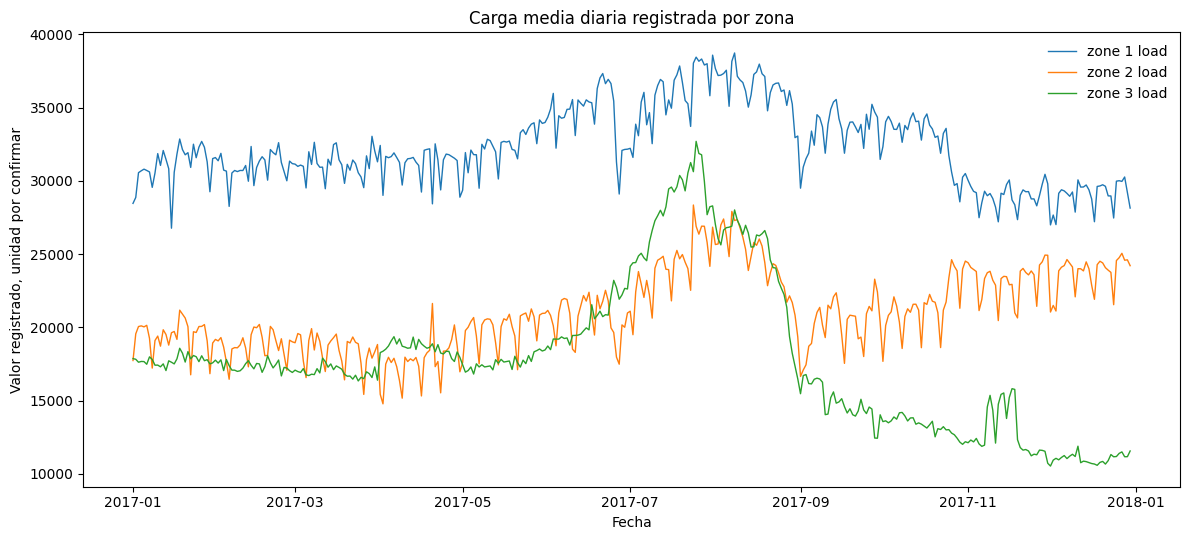

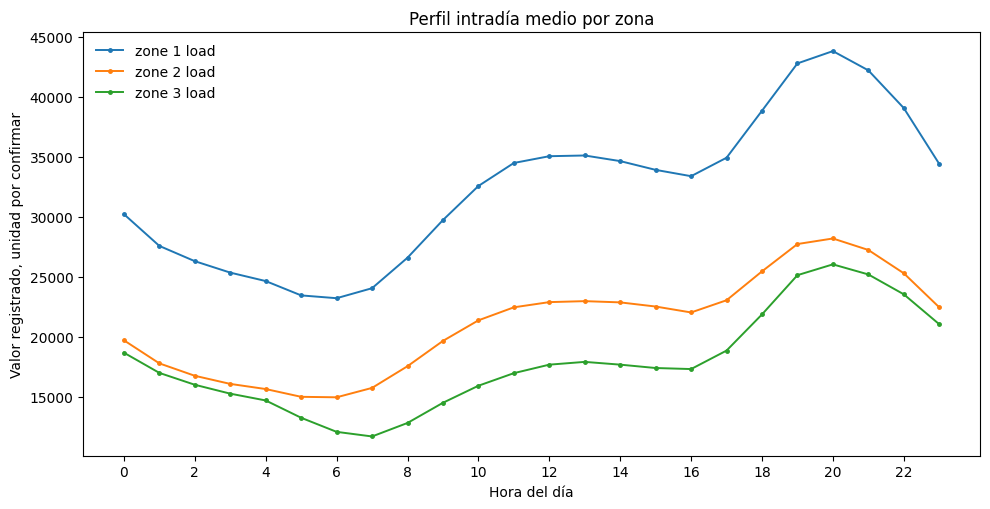

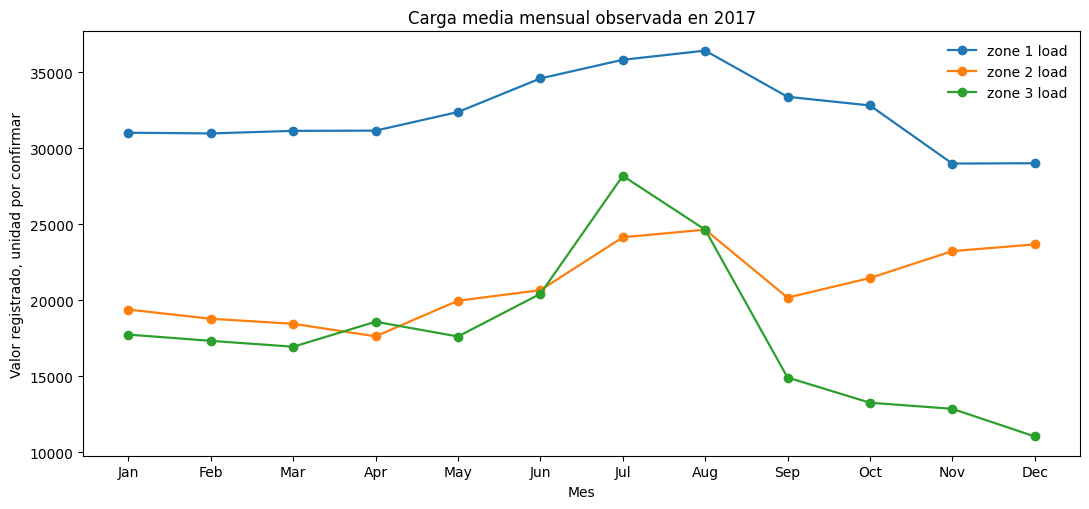

Perfil medio por día de la semana


,zone_1_load,zone_2_load,zone_3_load
weekday,,,
Monday,"32,615.410","21,280.070","17,809.080"
Tuesday,"32,713.030","21,518.600","17,831.690"
Wednesday,"32,871.760","21,627.360","17,851.400"
Thursday,"32,842.480","21,845.160","17,843.690"
Friday,"32,339.000","21,461.040","17,545.970"
Saturday,"32,253.030","20,585.960","18,011.190"
Sunday,"30,780.080","18,979.380","17,954.830"


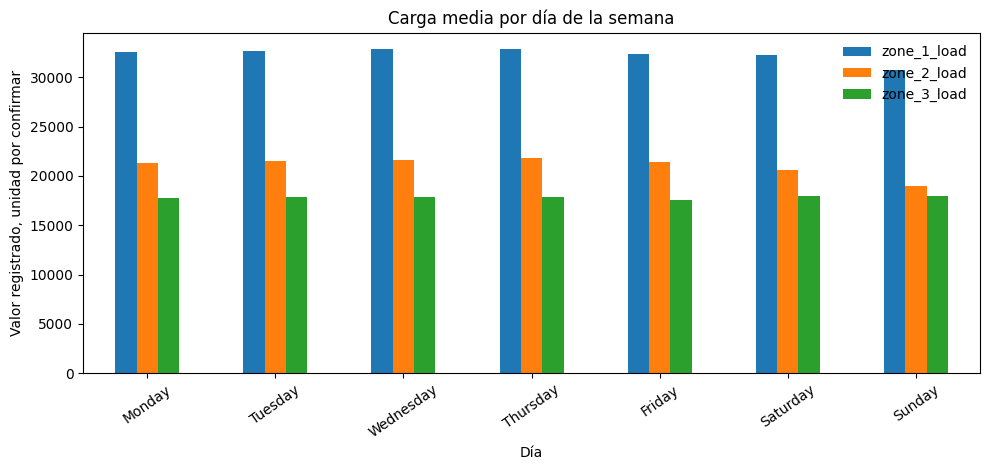

In [6]:
indexed = df.set_index("datetime").sort_index()
daily_load = indexed[load_cols].resample("D").mean()
monthly_load = indexed[load_cols].resample("MS").mean()
hourly_profile = indexed[load_cols].groupby(indexed.index.hour).mean()

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_profile = (
    df.assign(weekday=df["datetime"].dt.day_name())
      .groupby("weekday")[load_cols]
      .mean()
      .reindex(weekday_order)
)

fig, ax = plt.subplots(figsize=(12, 5.5))
for col in load_cols:
    ax.plot(daily_load.index, daily_load[col], linewidth=1.0, label=col.replace("_", " "))
ax.set_title("Carga media diaria registrada por zona")
ax.set_xlabel("Fecha")
ax.set_ylabel("Valor registrado, unidad por confirmar")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_daily_load_by_zone.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 5.2))
for col in load_cols:
    ax.plot(hourly_profile.index, hourly_profile[col], marker="o", markersize=2.5, linewidth=1.4, label=col.replace("_", " "))
ax.set_title("Perfil intradía medio por zona")
ax.set_xlabel("Hora del día")
ax.set_ylabel("Valor registrado, unidad por confirmar")
ax.set_xticks(range(0, 24, 2))
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_intraday_profile.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(11, 5.2))
for col in load_cols:
    ax.plot(monthly_load.index.strftime("%b"), monthly_load[col].values, marker="o", linewidth=1.6, label=col.replace("_", " "))
ax.set_title("Carga media mensual observada en 2017")
ax.set_xlabel("Mes")
ax.set_ylabel("Valor registrado, unidad por confirmar")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_monthly_profile.png", dpi=160, bbox_inches="tight")
plt.show()

print("Perfil medio por día de la semana")
display(weekday_profile.round(2))

fig, ax = plt.subplots(figsize=(10, 4.8))
weekday_profile.plot(kind="bar", ax=ax)
ax.set_title("Carga media por día de la semana")
ax.set_xlabel("Día")
ax.set_ylabel("Valor registrado, unidad por confirmar")
ax.tick_params(axis="x", rotation=35)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_weekday_profile.png", dpi=160, bbox_inches="tight")
plt.show()

### **2.7. Investigar el cambio entre agosto y septiembre**

El perfil mensual identifica una caída marcada de Zone 3 entre agosto y septiembre. Este bloque cuantifica el cambio para las tres zonas y mantiene el hallazgo como una pregunta abierta. El cálculo no explica la causa ni justifica eliminar registros.

In [7]:
monthly_change_pct = monthly_load.pct_change().mul(100)
monthly_change_pct.index = monthly_change_pct.index.strftime("%Y-%m")

print("Variación porcentual de la carga media mensual respecto al mes anterior")
display(monthly_change_pct.round(1))

august = monthly_load.loc[pd.Timestamp("2017-08-01")]
september = monthly_load.loc[pd.Timestamp("2017-09-01")]
aug_sep_review = pd.DataFrame({
    "media_agosto": august,
    "media_septiembre": september,
    "variacion_pct": ((september / august) - 1) * 100,
})
display(aug_sep_review.round(2))

print(
    "Interpretación: revisar la caída por zona frente al histórico diario, "
    "la definición de la variable y la documentación del operador antes de atribuir causas."
)

Variación porcentual de la carga media mensual respecto al mes anterior


,zone_1_load,zone_2_load,zone_3_load
datetime,,,
2017-01,NaN,NaN,NaN
2017-02,-0.200,-3.100,-2.300
2017-03,0.500,-1.800,-2.200
2017-04,0.000,-4.500,9.700
2017-05,3.900,13.300,-5.200
2017-06,6.800,3.500,15.900
2017-07,3.500,16.800,38.000
2017-08,1.700,2.100,-12.600
2017-09,-8.300,-18.200,-39.500


,media_agosto,media_septiembre,variacion_pct
zone_1_load,"36,435.190","33,396.680",-8.340
zone_2_load,"24,656.220","20,180.430",-18.150
zone_3_load,"24,648.890","14,922.800",-39.460


Interpretación: revisar la caída por zona frente al histórico diario, la definición de la variable y la documentación del operador antes de atribuir causas.


**2.7.1. Preguntas de investigación para este hallazgo**

1. ¿La caída se concentra en una fecha concreta o ocurre gradualmente durante varias semanas?
2. ¿La escala de Zone 3 cambia de forma similar en la fuente original y en publicaciones que usaron el mismo dataset?
3. ¿Existe documentación que explique la medida, la cobertura de la red o posibles ajustes del sistema de medición?
4. ¿Qué efecto tendría conservar el periodo en el entrenamiento y en el error de los pronósticos?

Por ahora no se elige un tratamiento. El valor del hallazgo consiste en evitar que un cambio importante quede oculto durante la preparación del dataset.

### **2.8. Revisar relaciones entre zonas y variables ambientales**

La correlación de Pearson resume asociaciones lineales entre columnas. En datos temporales, los ciclos compartidos y las tendencias pueden generar correlaciones elevadas incluso cuando no existe una relación causal directa. Las variables meteorológicas solo podrán evaluarse como predictores después de definir qué información estaría disponible al momento de emitir el pronóstico.

Correlación lineal entre las zonas


,zone_1_load,zone_2_load,zone_3_load
zone_1_load,1.000,0.835,0.751
zone_2_load,0.835,1.000,0.571
zone_3_load,0.751,0.571,1.000


Correlación lineal entre variables ambientales y carga


,zone_1_load,zone_2_load,zone_3_load
temperature,0.440,0.382,0.489
humidity,-0.287,-0.295,-0.233
wind_speed,0.167,0.146,0.279
general_diffuse_flows,0.188,0.157,0.063
diffuse_flows,0.080,0.045,-0.038


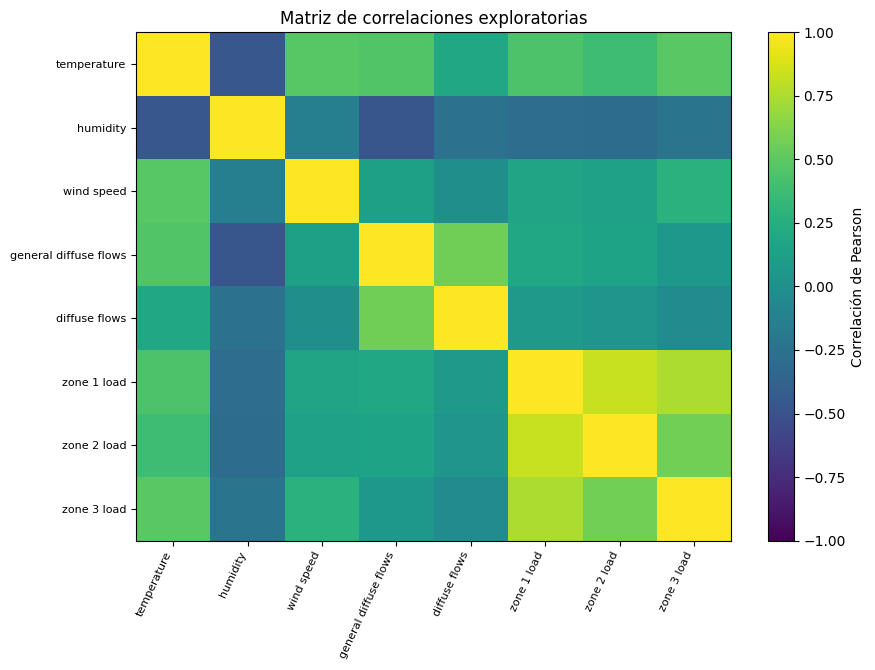

In [8]:
zone_corr = df[load_cols].corr().round(4)
weather_corr = df[weather_cols + load_cols].corr(numeric_only=True).loc[weather_cols, load_cols].round(4)

print("Correlación lineal entre las zonas")
display(zone_corr)
print("Correlación lineal entre variables ambientales y carga")
display(weather_corr)

corr_matrix = df[weather_cols + load_cols].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(9, 6.8))
image = ax.imshow(corr_matrix.values, vmin=-1, vmax=1, aspect="auto")
fig.colorbar(image, ax=ax, label="Correlación de Pearson")
ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_xticklabels([name.replace("_", " ") for name in corr_matrix.columns], rotation=65, ha="right", fontsize=8)
ax.set_yticks(range(len(corr_matrix.index)))
ax.set_yticklabels([name.replace("_", " ") for name in corr_matrix.index], fontsize=8)
ax.set_title("Matriz de correlaciones exploratorias")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_correlation_matrix.png", dpi=160, bbox_inches="tight")
plt.show()

### **2.9. Revisar rangos sin eliminar extremos automáticamente**

Se inspeccionan mínimos, máximos, medias, medianas, dispersión y cuantiles extremos. Un valor inusual puede ser real y relevante. Una limpieza posterior requerirá una regla con fundamento y un análisis de sensibilidad cuando la decisión pueda afectar los resultados.

In [9]:
range_review = df[load_cols + weather_cols].agg(["min", "max", "mean", "median", "std"]).T
range_review["p01"] = df[load_cols + weather_cols].quantile(0.01)
range_review["p99"] = df[load_cols + weather_cols].quantile(0.99)
display(range_review.round(3))

,min,max,mean,median,std,p01,p99
zone_1_load,"13,895.696","52,204.395","32,344.971","32,265.920","7,130.563","20,274.815","48,099.484"
zone_2_load,"8,560.081","37,408.861","21,042.509","20,823.168","5,201.466","11,631.696","33,734.949"
zone_3_load,"5,935.174","47,598.326","17,835.406","16,415.117","6,622.165","7,726.265","38,722.444"
temperature,3.247,40.010,18.810,18.780,5.815,6.764,33.158
humidity,11.340,94.800,68.260,69.860,15.551,27.332,92.000
wind_speed,0.050,6.483,1.959,0.086,2.349,0.066,4.928
general_diffuse_flows,0.004,"1,163.000",182.697,5.036,264.401,0.022,885.000
diffuse_flows,0.011,936.000,75.028,4.456,124.211,0.059,596.800


### **2.10. Resumen ejecutivo de la exploración**

**2.10.1. Hallazgos confirmados por el archivo**

- El CSV local contiene 52.416 registros y nueve columnas.
- La frecuencia observada es de diez minutos, sin nulos, filas duplicadas, marcas de tiempo repetidas ni huecos internos entre registros presentes.
- La cobertura termina el 30 de diciembre de 2017 a las 23:50, antes de completar el año calendario. La diferencia con el número de instancias informado por UCI también queda pendiente.
- Las tres zonas exhiben niveles de carga distintos, por lo que se conservarán por separado durante la primera comparación de modelos.
- La media mensual de Zone 3 cae de forma marcada entre agosto y septiembre. La causa no se puede determinar con este análisis.

**2.10.2. Límites que afectan decisiones posteriores**

- Las unidades físicas no están completas en la ficha de UCI. No convertir carga a kWh hasta confirmar la semántica de la medida.
- Un único año incompleto no permite evaluar la variabilidad entre años.
- El histórico de 2017 no proporciona mediciones de demanda actuales.
- El clima observado en el periodo objetivo no representa automáticamente una variable disponible al emitir un pronóstico histórico.
- No hay tarifas, costos, capacidad nominal ni eventos operativos para afirmar ahorros, costos evitados o riesgo físico de sobrecarga.

**2.10.3. Decisiones que quedan pendientes**

1. Buscar si existe una versión íntegra del archivo y registrar la versión definitiva.
2. Confirmar, con documentación primaria, las unidades y la semántica de las variables objetivo.
3. Definir una agregación temporal adecuada para el horizonte operativo. La agregación debe respetar la variable física una vez confirmada.
4. Diseñar una partición temporal y un protocolo de backtesting antes de entrenar.
5. Construir líneas base de 24 horas y siete días, por zona, antes de comparar modelos complejos.
6. Definir el umbral de demanda alta usando únicamente los datos de entrenamiento.

### **2.11. Exportar salidas reproducibles**

El notebook genera archivos derivados sin sobrescribir el CSV fuente. El dataset exportado aplica únicamente la estandarización de nombres y la interpretación de la fecha. Se considera una versión inicial del conjunto de datos, no el dataset final de modelado.

In [10]:
# La salida es una representación estandarizada del archivo, no una imputación ni una limpieza de extremos.
clean_output = df.copy()
clean_output.to_csv(
    PROCESSED_DATA_DIR / "Tetouan_Clean_v1.csv",
    index=False,
    date_format="%Y-%m-%d %H:%M:%S",
    encoding="utf-8-sig",
)

dictionary.to_csv(TABLES_DIR / "Tetouan_Data_Dictionary.csv", index=False, encoding="utf-8-sig")
quality_audit.to_csv(TABLES_DIR / "Tetouan_Data_Quality_Audit.csv", index=False, encoding="utf-8-sig")
load_summary.to_csv(TABLES_DIR / "Load_Descriptive_Statistics.csv", encoding="utf-8-sig")
weather_summary.to_csv(TABLES_DIR / "Weather_Descriptive_Statistics.csv", encoding="utf-8-sig")
monthly_load.to_csv(TABLES_DIR / "Monthly_Load_Profile.csv", encoding="utf-8-sig")
hourly_profile.to_csv(TABLES_DIR / "Hourly_Load_Profile.csv", encoding="utf-8-sig")
weekday_profile.to_csv(TABLES_DIR / "Weekday_Load_Profile.csv", encoding="utf-8-sig")
zone_corr.to_csv(TABLES_DIR / "Zone_Load_Correlation.csv", encoding="utf-8-sig")
weather_corr.to_csv(TABLES_DIR / "Weather_Load_Correlation.csv", encoding="utf-8-sig")
range_review.to_csv(TABLES_DIR / "Range_Review.csv", encoding="utf-8-sig")

aug_sep_review.to_csv(TABLES_DIR / "August_September_Review.csv", encoding="utf-8-sig")

print("Archivos generados")
for path in sorted([*PROCESSED_DATA_DIR.glob("*.csv"), *TABLES_DIR.glob("*.csv"), *FIGURES_DIR.glob("*.png")]):
    print(f"{path.relative_to(PROJECT_ROOT)} | {path.stat().st_size:,} bytes")

Archivos generados
data\processed\Tetouan_Clean_v1.csv | 4,482,850 bytes
reports\figures\01_daily_load_by_zone.png | 218,919 bytes
reports\figures\02_intraday_profile.png | 101,236 bytes
reports\figures\03_monthly_profile.png | 99,496 bytes
reports\figures\04_weekday_profile.png | 60,563 bytes
reports\figures\05_correlation_matrix.png | 75,284 bytes
reports\tables\August_September_Review.csv | 255 bytes
reports\tables\Hourly_Load_Profile.csv | 1,473 bytes
reports\tables\Load_Descriptive_Statistics.csv | 344 bytes
reports\tables\Monthly_Load_Profile.csv | 858 bytes
reports\tables\Range_Review.csv | 822 bytes
reports\tables\Tetouan_Data_Dictionary.csv | 2,098 bytes
reports\tables\Tetouan_Data_Quality_Audit.csv | 844 bytes
reports\tables\Weather_Descriptive_Statistics.csv | 434 bytes
reports\tables\Weather_Load_Correlation.csv | 220 bytes
reports\tables\Weekday_Load_Profile.csv | 503 bytes
reports\tables\Zone_Load_Correlation.csv | 134 bytes


### **2.12. Referencias y procedencia**

**2.12.1. Fuente del dataset**

Salam, A., & El Hibaoui, A. (2018). *Power Consumption of Tetouan City* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5B034. Licencia declarada por UCI: CC BY 4.0.

**2.12.2. Artículo original asociado**

Salam, A., & El Hibaoui, A. (2018). *Comparison of Machine Learning Algorithms for the Power Consumption Prediction: Case Study of Tetouan city*. 2018 6th International Renewable and Sustainable Energy Conference (IRSEC). https://doi.org/10.1109/IRSEC.2018.8703007

**2.12.3. Metodología CRISP-DM**

IBM. *IBM SPSS Modeler CRISP-DM Guide*. https://www.ibm.com/docs/en/SS3RA7_18.5.0/pdf/ModelerCRISPDM.pdf

---

**Criterio de cierre de Data Understanding:** los datos, la cobertura, los principales controles de calidad, los patrones observados y las incertidumbres están documentados. La siguiente fase debe tomar estas incertidumbres como decisiones explícitas, no resolverlas de forma silenciosa.

## **3. Data preparation**

En esta fase se definirá una transformación reproducible desde el archivo original hasta el dataset de modelado. No se ejecutan transformaciones definitivas hasta resolver las incertidumbres identificadas en la comprensión de los datos.

### **3.1. Selección y limpieza de datos**

Antes de corregir o excluir observaciones, se compara el cambio de nivel entre zonas con las variables ambientales. La revisión busca distinguir un valor aislado de un posible cambio de régimen. No atribuye causas ni modifica la fuente.

In [11]:
daily_prep = df.set_index("datetime").sort_index().resample("D").mean(numeric_only=True)
monthly_prep = daily_prep.resample("MS").mean(numeric_only=True)

aug_sep = pd.DataFrame({
    "media_agosto": monthly_prep.loc["2017-08-01", load_cols],
    "media_septiembre": monthly_prep.loc["2017-09-01", load_cols],
})
aug_sep["variacion_pct"] = (aug_sep["media_septiembre"] / aug_sep["media_agosto"] - 1) * 100
print("Cambio de la carga media entre agosto y septiembre")
display(aug_sep.round(1))

print("Evolución diaria de Zone 3 y Wind Speed alrededor del cambio")
display(daily_prep.loc["2017-08-28":"2017-09-06", ["zone_3_load", "wind_speed"]].round(2))

Cambio de la carga media entre agosto y septiembre


,media_agosto,media_septiembre,variacion_pct
zone_1_load,"36,435.200","33,396.700",-8.300
zone_2_load,"24,656.200","20,180.400",-18.200
zone_3_load,"24,648.900","14,922.800",-39.500


Evolución diaria de Zone 3 y Wind Speed alrededor del cambio


,zone_3_load,wind_speed
datetime,,
2017-08-28,"19,365.600",4.920
2017-08-29,"18,224.990",4.920
2017-08-30,"17,351.720",4.920
2017-08-31,"16,486.140",4.920
2017-09-01,"15,470.850",4.920
2017-09-02,"16,712.070",4.930
2017-09-03,"16,778.260",3.820
2017-09-04,"16,164.170",0.240
2017-09-05,"16,140.140",0.290


La media de Zone 3 cae cerca de 39,5 % entre agosto y septiembre. Zone 2 también disminuye, mientras que Zone 1 cambia menos. En esos mismos días, la media diaria de `wind_speed` pasa de valores cercanos a 4,92 a aproximadamente 0,24. La coincidencia temporal es una señal para investigar la estabilidad de las mediciones, no una explicación causal. Por ahora no se eliminan registros ni se corrige ninguna variable. La comparación de modelos deberá conservar este periodo y revisar su influencia.

### **3.2. Definir resolución temporal y agregar observaciones**

Los objetivos se expresan a 24 horas y siete días. Para la primera comparación se usará una serie horaria candidata, que convierte esos horizontes en 24 y 168 pasos y conserva suficientes observaciones para evaluar patrones diarios y semanales. El artículo original compara pronósticos a diez minutos y por hora, pero la ficha de UCI no especifica las unidades físicas. Por eso se conserva la escala original y se interpreta la media horaria como una hipótesis de trabajo, no como energía acumulada.

In [12]:
source_indexed = df.set_index("datetime").sort_index()
records_per_hour = source_indexed[load_cols + weather_cols].resample("h").count()
incomplete_hours = records_per_hour.ne(6).any(axis=1)

if incomplete_hours.any():
    display(records_per_hour.loc[incomplete_hours].head(10))
    raise ValueError("Hay horas con distinto de seis registros. Revisar la cobertura antes de agregar.")

hourly_candidate = source_indexed[load_cols + weather_cols].resample("h").mean()

print(f"Horas completas: {len(hourly_candidate):,}")
print(f"Horizonte de 24 horas: 24 pasos | Horizonte de 7 días: {7 * 24} pasos")
display(hourly_candidate.head(3))

Horas completas: 8,736
Horizonte de 24 horas: 24 pasos | Horizonte de 7 días: 168 pasos


,zone_1_load,zone_2_load,zone_3_load,temperature,humidity,wind_speed,general_diffuse_flows,diffuse_flows
datetime,,,,,,,,
2017-01-01 00:00:00,"29,197.975","18,026.748","19,252.048",6.197,75.067,0.082,0.064,0.099
2017-01-01 01:00:00,"24,657.215","16,078.419","17,042.892",5.549,77.583,0.082,0.057,0.113
2017-01-01 02:00:00,"22,083.038","14,330.699","15,676.145",5.054,78.933,0.082,0.063,0.129


La serie candidata contiene 8.736 horas completas. La agregación calcula la media de los seis registros observados en cada hora y no suma sus valores. Esto es adecuado si cada registro representa un nivel de carga; si la variable representa energía consumida durante cada intervalo, la regla tendría que cambiar. UCI deja las unidades sin especificar, por lo que no se etiquetará la serie como kW ni se convertirá a kWh hasta confirmar la semántica de la medición. El artículo asociado estudia ambas frecuencias: [Salam y El Hibaoui (2018)](https://doi.org/10.1109/IRSEC.2018.8703007).

### **3.3. Integración y formato del dataset**

Se verifica que la serie horaria derivada mantenga continuidad, valores completos y trazabilidad temporal. Esta comprobación se realiza sobre el objeto candidato en memoria; todavía no se publica un nuevo CSV de modelado.

In [13]:
hourly_gaps = hourly_candidate.index.to_series().diff().dropna()
preparation_audit = pd.DataFrame([
    ("Observaciones horarias", len(hourly_candidate)),
    ("Primera hora", hourly_candidate.index.min()),
    ("Última hora", hourly_candidate.index.max()),
    ("Columnas", hourly_candidate.shape[1]),
    ("Celdas nulas", int(hourly_candidate.isna().sum().sum())),
    ("Horas duplicadas", int(hourly_candidate.index.duplicated().sum())),
    ("Intervalos distintos de una hora", int((hourly_gaps != pd.Timedelta(hours=1)).sum())),
], columns=["control", "resultado"])
display(preparation_audit)

,control,resultado
0,Observaciones horarias,8736
1,Primera hora,2017-01-01 00:00:00
2,Última hora,2017-12-30 23:00:00
3,Columnas,8
4,Celdas nulas,0
5,Horas duplicadas,0
6,Intervalos distintos de una hora,0


La serie horaria candidata conserva las 8.736 horas observadas, sin duplicados, nulos ni huecos horarios internos. No se imputa el 31 de diciembre que falta en el archivo fuente. Como esta salida se puede reconstruir desde `df`, se mantiene en memoria y no se crea todavía otro archivo procesado.

### **3.4. Definir particiones cronológicas**

Los cortes se calculan a partir de la última hora disponible, de modo que se adapten si se actualiza la fuente. La validación sirve para comparar y seleccionar candidatos; el bloque de prueba se reserva para la evaluación final.

In [14]:
last_hour = hourly_candidate.index.max()
test_start = last_hour.normalize() - pd.Timedelta(days=27)
validation_start = test_start - pd.Timedelta(days=28)
train_end = validation_start - pd.Timedelta(hours=1)
validation_end = test_start - pd.Timedelta(hours=1)

train_data = hourly_candidate.loc[:train_end].copy()
validation_data = hourly_candidate.loc[validation_start:validation_end].copy()
test_data = hourly_candidate.loc[test_start:last_hour].copy()

split_summary = pd.DataFrame([
    ("Train", train_data.index.min(), train_data.index.max(), len(train_data)),
    ("Validation", validation_data.index.min(), validation_data.index.max(), len(validation_data)),
    ("Test", test_data.index.min(), test_data.index.max(), len(test_data)),
], columns=["particion", "inicio", "fin", "horas"])
display(split_summary)
print("Cada bloque de validación y prueba abarca cuatro ventanas completas de siete días.")

,particion,inicio,fin,horas
0,Train,2017-01-01,2017-11-04 23:00:00,7392
1,Validation,2017-11-05,2017-12-02 23:00:00,672
2,Test,2017-12-03,2017-12-30 23:00:00,672


Cada bloque de validación y prueba abarca cuatro ventanas completas de siete días.


La partición es cronológica y no mezcla filas aleatoriamente. Las decisiones de modelado se tomarán con entrenamiento y validación; el test no se usará para elegir hiperparámetros. En la fase de evaluación, cada pronóstico se generará solo con la información disponible en su fecha de origen. Las variables meteorológicas observadas durante el horizonte futuro no se usarán como si se conocieran de antemano. Para incorporarlas a un pronóstico operativo hará falta una fuente de pronósticos meteorológicos o un diseño de evaluación que respete su disponibilidad.

**Criterio para pasar a Modeling.** La serie horaria se utilizará como resolución de trabajo provisional, sin cambiar las unidades ni eliminar el periodo de cambio de nivel. Antes de interpretar los errores en términos físicos, debe confirmarse la semántica de la variable objetivo. La primera comparación será contra líneas base temporales bajo estas mismas particiones.

## **4. Modeling**

Esta fase comparará métodos de forecasting para los horizontes definidos. La complejidad del modelo solo se justificará si aporta valor frente a una línea base sencilla bajo el mismo protocolo de evaluación.

### **4.1. Selección de técnicas y diseño de prueba**

Antes de entrenar modelos más complejos, se mide una referencia sencilla. La persistencia repite el último valor observado; la baseline estacional repite el perfil de las últimas 24 horas para el horizonte diario y el perfil de las últimas 168 horas para el horizonte semanal. La comparación se hace con orígenes móviles en validación, por zona, sin consultar el bloque de prueba. Se reportan MAE, RMSE y WAPE. Las dos primeras métricas permanecen en la escala original de la variable, cuya unidad aún no está confirmada.

In [15]:
def backtest_naive_baselines(series, evaluation, zones):
    results = []
    settings = [("24 horas", 24, "24h"), ("7 días", 168, "168h")]

    for horizon_name, steps, origin_frequency in settings:
        last_start = evaluation.index.max() - pd.Timedelta(hours=steps - 1)
        target_starts = pd.date_range(evaluation.index.min(), last_start, freq=origin_frequency)

        for target_start in target_starts:
            origin = target_start - pd.Timedelta(hours=1)
            history = series.loc[:origin]
            target_index = pd.date_range(target_start, periods=steps, freq="h")
            actual = series.loc[target_index, zones]

            for zone in zones:
                forecasts = {
                    "Persistencia": np.repeat(history[zone].iloc[-1], steps),
                    "Estacional": history[zone].iloc[-steps:].to_numpy(),
                }
                for baseline, prediction in forecasts.items():
                    for timestamp, y_true, y_pred in zip(target_index, actual[zone], prediction):
                        results.append((horizon_name, target_start, zone, baseline, timestamp, y_true, y_pred))

    return pd.DataFrame(
        results,
        columns=["horizonte", "inicio_pronostico", "zona", "baseline", "datetime", "real", "predicho"],
    )

validation_predictions = backtest_naive_baselines(hourly_candidate, validation_data, load_cols)
validation_predictions["error_absoluto"] = (validation_predictions["real"] - validation_predictions["predicho"]).abs()
validation_predictions["error_cuadrado"] = (validation_predictions["real"] - validation_predictions["predicho"]) ** 2
validation_predictions["real_absoluto"] = validation_predictions["real"].abs()

validation_metrics = (
    validation_predictions.groupby(["horizonte", "zona", "baseline"])
    .agg(
        MAE=("error_absoluto", "mean"),
        RMSE=("error_cuadrado", lambda values: np.sqrt(values.mean())),
        error_absoluto_total=("error_absoluto", "sum"),
        valor_absoluto_total=("real_absoluto", "sum"),
        observaciones=("real", "size"),
    )
    .reset_index()
)
validation_metrics["WAPE_pct"] = 100 * validation_metrics["error_absoluto_total"] / validation_metrics["valor_absoluto_total"]

print("Orígenes evaluados:")
print("24 horas:", validation_predictions.loc[validation_predictions["horizonte"] == "24 horas", "inicio_pronostico"].nunique())
print("7 días:", validation_predictions.loc[validation_predictions["horizonte"] == "7 días", "inicio_pronostico"].nunique())
display(validation_metrics[["horizonte", "zona", "baseline", "MAE", "RMSE", "WAPE_pct", "observaciones"]].round(2))

Orígenes evaluados:
24 horas: 28
7 días: 4


,horizonte,zona,baseline,MAE,RMSE,WAPE_pct,observaciones
0,24 horas,zone_1_load,Estacional,990.100,"1,444.840",3.440,672
1,24 horas,zone_1_load,Persistencia,"5,022.900","5,911.200",17.440,672
2,24 horas,zone_2_load,Estacional,"1,305.730","1,929.320",5.680,672
3,24 horas,zone_2_load,Persistencia,"4,650.980","5,454.650",20.240,672
4,24 horas,zone_3_load,Estacional,993.840,"1,740.160",7.770,672
5,24 horas,zone_3_load,Persistencia,"3,073.630","3,399.470",24.020,672
6,7 días,zone_1_load,Estacional,908.200,"1,228.090",3.150,672
7,7 días,zone_1_load,Persistencia,"5,035.990","5,952.320",17.480,672
8,7 días,zone_2_load,Estacional,"1,111.770","1,511.540",4.840,672
9,7 días,zone_2_load,Persistencia,"4,657.440","5,464.620",20.270,672


La baseline estacional supera a la persistencia en las tres zonas y en ambos horizontes, por lo que el perfil de la semana o del día anterior ofrece una referencia más útil que repetir un único valor. El error relativo es mayor en Zone 3, especialmente a siete días, consistente con la necesidad de investigar su cambio de nivel. Estos resultados son de validación, no de prueba final, y las métricas absolutas conservan la unidad nativa aún no documentada. Los modelos candidatos deberán superar esta baseline con las mismas particiones y orígenes para demostrar valor incremental.

### **4.2. Entrenar modelos candidatos**

Se compararán dos candidatos de machine learning por zona y horizonte: Random Forest y HistGradientBoosting. Ambos recibirán variables de calendario y rezagos de la carga. Se entrenarán modelos directos para 24 y 168 pasos, de modo que cada predicción use solo observaciones disponibles en el origen y no dependa de alimentar predicciones previas al modelo.

**4.2.1. Construir variables disponibles al emitir el pronóstico**

Las variables incluyen calendario, último valor conocido, rezagos de 24 y 168 horas, medias recientes y la observación estacional correspondiente al horizonte. Esta última está disponible en el origen del pronóstico. No se incorporan variables meteorológicas observadas dentro del periodo futuro.

In [16]:
FEATURE_COLUMNS = [
    "target_hour", "target_day_of_week", "target_month", "target_is_weekend", "lead",
    "last_observed", "lag_24_at_origin", "lag_168_at_origin",
    "mean_prev_24", "mean_prev_168", "seasonal_lag",
]


def direct_features(values, index, origin_idx, horizon):
    target_idx = np.arange(origin_idx + 1, origin_idx + horizon + 1)
    target_times = index[target_idx]
    return pd.DataFrame({
        "target_hour": target_times.hour,
        "target_day_of_week": target_times.dayofweek,
        "target_month": target_times.month,
        "target_is_weekend": (target_times.dayofweek >= 5).astype(int),
        "lead": np.arange(1, horizon + 1),
        "last_observed": values[origin_idx],
        "lag_24_at_origin": values[origin_idx - 24],
        "lag_168_at_origin": values[origin_idx - 168],
        "mean_prev_24": values[origin_idx - 23:origin_idx + 1].mean(),
        "mean_prev_168": values[origin_idx - 167:origin_idx + 1].mean(),
        "seasonal_lag": values[target_idx - horizon],
    }, index=target_times)[FEATURE_COLUMNS]


def direct_training_set(values, index, train_end_idx, horizon, origin_step, first_origin_idx):
    x_parts, y_parts = [], []
    last_origin_idx = train_end_idx - horizon
    for origin_idx in range(first_origin_idx, last_origin_idx + 1, origin_step):
        x_parts.append(direct_features(values, index, origin_idx, horizon))
        y_parts.append(values[origin_idx + 1:origin_idx + horizon + 1])
    return pd.concat(x_parts), np.concatenate(y_parts)

**4.2.2. Entrenar candidatos por zona y horizonte**

Se ajusta cada modelo con ventanas objetivo que terminan dentro del periodo de entrenamiento. Después se generan pronósticos para los mismos orígenes de validación usados por las baselines. El conjunto de prueba no interviene en el ajuste ni en la elección de candidatos.

In [17]:
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor

model_factories = {
    "Random Forest": lambda: RandomForestRegressor(
        n_estimators=80, min_samples_leaf=5, random_state=42, n_jobs=1
    ),
    "HistGradientBoosting": lambda: HistGradientBoostingRegressor(
        max_iter=100, learning_rate=0.06, max_leaf_nodes=15,
        l2_regularization=1.0, random_state=42
    ),
}
horizon_settings = [("24 horas", 24, 24, 24 * 7 + 23), ("7 días", 168, 168, 167)]
train_end_idx = hourly_candidate.index.get_loc(train_data.index.max())
model_validation_rows, fitted_models = [], {}

for zone in load_cols:
    values = hourly_candidate[zone].to_numpy()
    for horizon_name, steps, origin_step, first_origin_idx in horizon_settings:
        x_train, y_train = direct_training_set(
            values, hourly_candidate.index, train_end_idx, steps, origin_step, first_origin_idx
        )
        for model_name, factory in model_factories.items():
            model = factory().fit(x_train, y_train)
            fitted_models[(zone, horizon_name, model_name)] = model

            last_start_idx = hourly_candidate.index.get_loc(validation_data.index.max()) - steps + 1
            first_start_idx = hourly_candidate.index.get_loc(validation_data.index.min())
            for target_start_idx in range(first_start_idx, last_start_idx + 1, steps):
                origin_idx = target_start_idx - 1
                target_idx = np.arange(target_start_idx, target_start_idx + steps)
                x_future = direct_features(values, hourly_candidate.index, origin_idx, steps)
                prediction = model.predict(x_future)
                for timestamp, actual, predicted in zip(
                    hourly_candidate.index[target_idx], values[target_idx], prediction
                ):
                    model_validation_rows.append((
                        horizon_name, hourly_candidate.index[target_start_idx], zone,
                        model_name, timestamp, actual, predicted
                    ))

candidate_predictions = pd.DataFrame(
    model_validation_rows,
    columns=["horizonte", "inicio_pronostico", "zona", "baseline", "datetime", "real", "predicho"],
)
print(f"Modelos ajustados: {len(fitted_models)}")
print(f"Predicciones generadas en validación: {len(candidate_predictions):,}")

Modelos ajustados: 12
Predicciones generadas en validación: 8,064


### **4.3. Comparar candidatos en validación**

Las métricas se calculan sobre los mismos instantes de validación para las baselines y los dos modelos candidatos. La mejora porcentual se compara contra la baseline estacional. Un valor positivo indica menor MAE; un valor negativo indica que el candidato empeora la referencia.

In [18]:
baseline_rows = validation_predictions[
    ["horizonte", "inicio_pronostico", "zona", "baseline", "datetime", "real", "predicho"]
]
comparison_predictions = pd.concat([baseline_rows, candidate_predictions], ignore_index=True)
comparison_predictions["error_absoluto"] = (
    comparison_predictions["real"] - comparison_predictions["predicho"]
).abs()
comparison_predictions["error_cuadrado"] = (
    comparison_predictions["real"] - comparison_predictions["predicho"]
) ** 2
comparison_predictions["real_absoluto"] = comparison_predictions["real"].abs()

model_comparison = (
    comparison_predictions.groupby(["horizonte", "zona", "baseline"])
    .agg(
        MAE=("error_absoluto", "mean"),
        RMSE=("error_cuadrado", lambda values: np.sqrt(values.mean())),
        error_absoluto_total=("error_absoluto", "sum"),
        valor_absoluto_total=("real_absoluto", "sum"),
    )
    .reset_index()
)
model_comparison["WAPE_pct"] = 100 * model_comparison["error_absoluto_total"] / model_comparison["valor_absoluto_total"]
seasonal_mae = model_comparison.loc[
    model_comparison["baseline"] == "Estacional", ["horizonte", "zona", "MAE"]
].rename(columns={"MAE": "MAE_estacional"})
model_comparison = model_comparison.merge(seasonal_mae, on=["horizonte", "zona"], how="left")
model_comparison["mejora_MAE_pct"] = 100 * (
    model_comparison["MAE_estacional"] - model_comparison["MAE"]
) / model_comparison["MAE_estacional"]

display(model_comparison[[
    "horizonte", "zona", "baseline", "MAE", "RMSE", "WAPE_pct", "mejora_MAE_pct"
]].round(2))

,horizonte,zona,baseline,MAE,RMSE,WAPE_pct,mejora_MAE_pct
0,24 horas,zone_1_load,Estacional,990.100,"1,444.840",3.440,0.000
1,24 horas,zone_1_load,HistGradientBoosting,"1,030.100","1,390.550",3.580,-4.040
2,24 horas,zone_1_load,Persistencia,"5,022.900","5,911.200",17.440,-407.310
3,24 horas,zone_1_load,Random Forest,"1,159.470","1,601.760",4.030,-17.110
4,24 horas,zone_2_load,Estacional,"1,305.730","1,929.320",5.680,0.000
5,24 horas,zone_2_load,HistGradientBoosting,971.000,"1,352.490",4.230,25.640
6,24 horas,zone_2_load,Persistencia,"4,650.980","5,454.650",20.240,-256.200
7,24 horas,zone_2_load,Random Forest,988.770,"1,382.380",4.300,24.270
8,24 horas,zone_3_load,Estacional,993.840,"1,740.160",7.770,0.000
9,24 horas,zone_3_load,HistGradientBoosting,"1,059.210","1,698.190",8.280,-6.580


En validación, HistGradientBoosting mejora la baseline estacional en Zone 2 para 24 horas, con una reducción de MAE cercana al 25,6 %. Para siete días, ambos modelos mejoran ligeramente la baseline en Zone 3, alrededor de 5 %. En las demás combinaciones, la baseline estacional mantiene menor MAE. Por ahora, la complejidad de machine learning no demuestra una mejora general. Conviene conservar la baseline estacional como referencia y profundizar únicamente en los casos donde el modelo añade valor. Estos resultados dependen de un solo año histórico incompleto y deben confirmarse al final con el test reservado.

## **5. Evaluation**

La evaluación determinará si el desempeño satisface los criterios de éxito del negocio y si las diferencias observadas son suficientemente consistentes para orientar decisiones. No se elegirá un modelo solo por una métrica agregada.

### **5.1. Evaluación de resultados**

La selección se fija usando únicamente MAE de validación. Luego se reentrenan los modelos elegidos con entrenamiento más validación y se evalúan una sola vez en el bloque test del 3 al 30 de diciembre. La baseline estacional se calcula como referencia en las mismas fechas. El test no interviene en la selección ni en el ajuste de parámetros.

In [19]:
selected_by_validation = model_comparison.loc[
    model_comparison.groupby(["horizonte", "zona"])["MAE"].idxmin(),
    ["horizonte", "zona", "baseline", "MAE"],
].rename(columns={"baseline": "metodo_seleccionado", "MAE": "MAE_validacion"})

fit_end_idx = hourly_candidate.index.get_loc(validation_data.index.max())
test_start_idx = hourly_candidate.index.get_loc(test_data.index.min())
test_end_idx = hourly_candidate.index.get_loc(test_data.index.max())
test_rows = []

for _, selected in selected_by_validation.iterrows():
    zone = selected["zona"]
    horizon_name = selected["horizonte"]
    method = selected["metodo_seleccionado"]
    steps = 24 if horizon_name == "24 horas" else 168
    first_origin_idx = 24 * 7 + 23 if steps == 24 else 167
    values = hourly_candidate[zone].to_numpy()
    model = None

    if method in model_factories:
        x_fit, y_fit = direct_training_set(
            values, hourly_candidate.index, fit_end_idx, steps, steps, first_origin_idx
        )
        model = model_factories[method]().fit(x_fit, y_fit)

    last_start_idx = test_end_idx - steps + 1
    for target_start_idx in range(test_start_idx, last_start_idx + 1, steps):
        origin_idx = target_start_idx - 1
        target_idx = np.arange(target_start_idx, target_start_idx + steps)
        actual = values[target_idx]
        seasonal = values[target_idx - steps]

        for timestamp, y_true, y_pred in zip(hourly_candidate.index[target_idx], actual, seasonal):
            test_rows.append((horizon_name, zone, "Estacional", timestamp, y_true, y_pred))

        if method == "Persistencia":
            prediction = np.repeat(values[origin_idx], steps)
        elif model is not None:
            prediction = model.predict(direct_features(values, hourly_candidate.index, origin_idx, steps))
        else:
            prediction = None

        if prediction is not None and method != "Estacional":
            for timestamp, y_true, y_pred in zip(hourly_candidate.index[target_idx], actual, prediction):
                test_rows.append((horizon_name, zone, method, timestamp, y_true, y_pred))

test_predictions = pd.DataFrame(
    test_rows, columns=["horizonte", "zona", "baseline", "datetime", "real", "predicho"]
)
test_predictions["error_absoluto"] = (test_predictions["real"] - test_predictions["predicho"]).abs()
test_predictions["error_cuadrado"] = (test_predictions["real"] - test_predictions["predicho"]) ** 2
test_predictions["real_absoluto"] = test_predictions["real"].abs()

test_metrics = (
    test_predictions.groupby(["horizonte", "zona", "baseline"])
    .agg(
        MAE=("error_absoluto", "mean"),
        RMSE=("error_cuadrado", lambda values: np.sqrt(values.mean())),
        error_absoluto_total=("error_absoluto", "sum"),
        valor_absoluto_total=("real_absoluto", "sum"),
    )
    .reset_index()
)
test_metrics["WAPE_pct"] = 100 * test_metrics["error_absoluto_total"] / test_metrics["valor_absoluto_total"]
seasonal_test_mae = test_metrics.loc[
    test_metrics["baseline"] == "Estacional", ["horizonte", "zona", "MAE"]
].rename(columns={"MAE": "MAE_estacional_test"})
test_metrics = test_metrics.merge(seasonal_test_mae, on=["horizonte", "zona"], how="left")
test_metrics["mejora_MAE_pct"] = 100 * (
    test_metrics["MAE_estacional_test"] - test_metrics["MAE"]
) / test_metrics["MAE_estacional_test"]

print("Método seleccionado con validación")
display(selected_by_validation.round(2))
print("Resultado del test reservado")
display(test_metrics[[
    "horizonte", "zona", "baseline", "MAE", "RMSE", "WAPE_pct", "mejora_MAE_pct"
]].round(2))

Método seleccionado con validación


,horizonte,zona,metodo_seleccionado,MAE_validacion
0,24 horas,zone_1_load,Estacional,990.100
5,24 horas,zone_2_load,HistGradientBoosting,971.000
8,24 horas,zone_3_load,Estacional,993.840
12,7 días,zone_1_load,Estacional,908.200
16,7 días,zone_2_load,Estacional,"1,111.770"
23,7 días,zone_3_load,Random Forest,"1,920.680"


Resultado del test reservado


,horizonte,zona,baseline,MAE,RMSE,WAPE_pct,mejora_MAE_pct
0,24 horas,zone_1_load,Estacional,936.660,"1,478.690",3.210,0.000
1,24 horas,zone_2_load,Estacional,986.090,"1,514.790",4.130,0.000
2,24 horas,zone_2_load,HistGradientBoosting,766.710,"1,007.770",3.210,22.250
3,24 horas,zone_3_load,Estacional,379.510,547.860,3.430,0.000
4,7 días,zone_1_load,Estacional,730.380,"1,019.140",2.510,0.000
5,7 días,zone_2_load,Estacional,781.870,"1,164.880",3.280,0.000
6,7 días,zone_3_load,Estacional,555.610,717.090,5.020,0.000
7,7 días,zone_3_load,Random Forest,"1,446.640","1,941.890",13.070,-160.370


El test confirma una mejora para Zone 2 a 24 horas: HistGradientBoosting reduce el MAE frente a la baseline estacional. En cambio, Random Forest no conserva la mejora semanal de Zone 3 y queda por detrás de la baseline en diciembre. Por tanto, no se justifica mantener el modelo complejo para ese caso. La baseline estacional sigue siendo la referencia para las otras combinaciones.

Esta evaluación usa solo cuatro semanas del mismo año y el archivo no incluye el 31 de diciembre. Los resultados son una prueba fuera de muestra dentro del periodo histórico, no evidencia de desempeño operativo actual ni de generalización entre años.

### **5.2. Revisión del proceso y siguientes decisiones**

La evidencia actual apoya mantener la baseline estacional en cinco de las seis combinaciones zona-horizonte y conservar HistGradientBoosting como candidato para Zone 2 a 24 horas. Antes de recomendar un pipeline operativo, revisar la semántica física de la variable objetivo, investigar el cambio de nivel de Zone 3 y definir cómo se obtendrán datos actuales. La evaluación debe revisarse si se dispone de una historia más larga o de una fuente de carga reciente.

## **6. Deployment**

El despliegue llevará los resultados validados a una salida consumible por el dashboard. Esta fase se diseñará después de definir y evaluar el pipeline, sin asumir que la ejecución manual del notebook será el mecanismo de actualización en operación.

### **6.1. Plan de despliegue**

**Pendiente.** Determinar qué transformaciones y modelo deben ejecutarse, qué entradas requieren, dónde se guarda cada salida y cómo se actualiza el dashboard. La arquitectura técnica se limitará a componentes que resuelvan una necesidad demostrada.

### **6.2. Monitorización y mantenimiento**

**Pendiente.** Definir controles de actualización, errores de ejecución, calidad de entradas y cambios de desempeño. Dado que la fuente actual solo incluye 2017, un despliegue operativo requerirá confirmar primero cómo obtener datos recientes de demanda.

### **6.3. Informe final y revisión del proyecto**

**Pendiente.** Consolidar la interpretación de negocio, resultados de modelos, limitaciones, decisiones recomendadas y oportunidades de mejora. El dashboard y el informe deben comunicar los resultados sin convertir asociaciones estadísticas en afirmaciones causales.